In [31]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw")
train = pd.read_csv(DATA_DIR / "dataset_train.csv", low_memory=False)
test = pd.read_csv(DATA_DIR / "dataset_test_X.csv", low_memory=False)

In [16]:
print("Treino:", train.shape)
print("Teste:", test.shape)

Treino: (10962, 237)
Teste: (3655, 236)


In [17]:
train.head()

,PID,HHID,PROXY,REFYEAR,REFMONTH,COUNTRY,NUTS1,REGION,NUTS2_AG,DEG_URB,...,IN10,IN11,IN12,IN13,IN14,IN55,IN56,IN57,IN59,IN67
0,1242.0,124201.0,1.0,2019,10,PT,Continente,Norte,Norte,Áreas densamente povoadas,...,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não
1,8881.0,888102.0,1.0,2020,1,PT,Continente,Alentejo,Alentejo,Áreas pouco povoadas,...,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não
2,399.0,39902.0,1.0,2019,12,PT,Continente,Norte,Norte,Áreas densamente povoadas,...,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Sem resposta,Não aplicável,Não aplicável,40.0,Não aplicável,Sim
3,10589.0,1058901.0,1.0,2019,11,PT,Continente,Alentejo,Lx V Tejo,Áreas mediamente povoadas,...,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não
4,6875.0,687501.0,1.0,2019,10,PT,Continente,Centro (PT),Lx V Tejo,Áreas pouco povoadas,...,Não,Não aplicável,Não aplicável,Não aplicável,"Doença, exceto doença profissional",Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não


In [18]:
train.dtypes.value_counts()

str        229
float64      5
int64        3
Name: count, dtype: int64


##
## Distribuição da variável "AGE_RANGE"

In [22]:
age_counts = train["AGE_RANGE"].value_counts()
age_counts = age_counts.sort_index()
print(age_counts)

AGE_RANGE
0      207
1      172
2      399
3      377
4      449
5      647
6      859
7      862
8      905
9     1014
10    1062
11    1040
12    1000
13     823
14     650
15     496
Name: count, dtype: int64


In [26]:
age_percentages = (train["AGE_RANGE"].value_counts(normalize=True).sort_index() * 100)
print(age_percentages.round(2))

AGE_RANGE
0     1.89
1     1.57
2     3.64
3     3.44
4     4.10
5     5.90
6     7.84
7     7.86
8     8.26
9     9.25
10    9.69
11    9.49
12    9.12
13    7.51
14    5.93
15    4.52
Name: proportion, dtype: float64


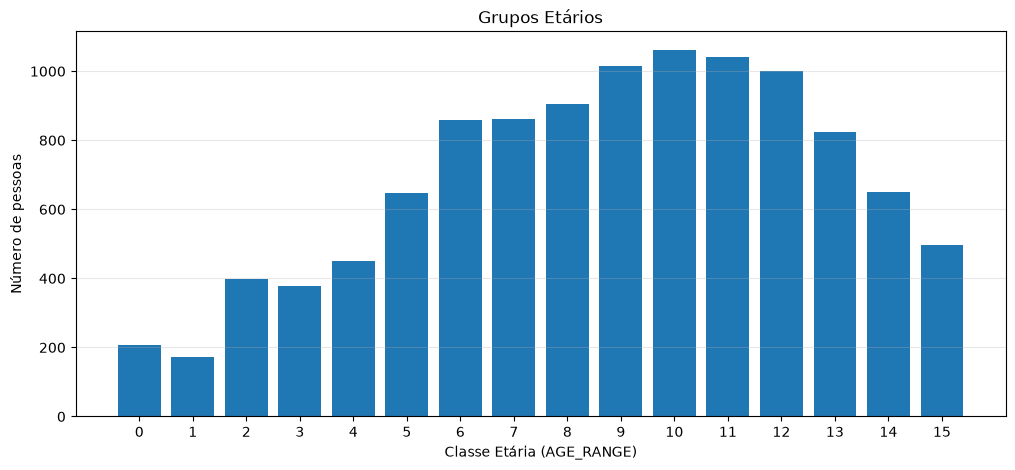

In [33]:
plt.figure(figsize = (12, 5))
plt.bar(age_counts.index, age_counts.values)
plt.title("Grupos Etários")
plt.xlabel("Classe Etária (AGE_RANGE)")
plt.ylabel("Número de pessoas")
plt.xticks(range(16))
plt.grid(axis="y", alpha=0.3)
plt.show()

## 
## Missing Values

In [44]:
missing_values = train.isna().sum()
missing_values = missing_values.sort_values(ascending=False)
missing_values.head()

IN16       5602
HHID          0
PROXY         0
REFYEAR       0
PID           0
dtype: int64

In [47]:
missin_percentage = train.isna().mean() * 100
missin_percentage = missin_percentage.sort_values(ascending=False)
missin_percentage.head()

IN16       51.103813
HHID        0.000000
PROXY       0.000000
REFYEAR     0.000000
PID         0.000000
dtype: float64